# **First Langgraph agent**

In [1]:
import os 
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")



In [2]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)


In [5]:
llm.invoke("Hi")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "Hi". Simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.083973068, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.003697581, 'prompt_tokens_details': None, 'queue_time': 0.158976484, 'total_time': 0.087670649}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4727af4560', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1d068-c7c8-7af1-9142-37508de5254c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})

## **step-1 Define Schema**

In [4]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    name: str
    message: str

## **step-2 creating the node functions**

In [6]:
def welcome(schema:graph_schema) -> graph_schema:

    current_name = schema['name']
    cuurent_message = schema['message']

    response = llm.invoke(f"My name is {current_name} and my message is {cuurent_message}").content

    schema['message'] = f"your messgae was {cuurent_message} :- and here is my response {response}"

    return schema



## **Step-3 Create State Graph**

In [7]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

# adding nodes:

graph.add_node("welcome",welcome)

## add edges

graph.add_edge(START,"welcome")
graph.add_edge("welcome",END)


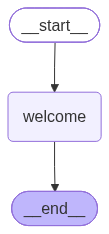

In [8]:
from IPython.display import Image, display

first_graph = graph.compile()

Image(first_graph.get_graph().draw_mermaid_png())

In [11]:
print(first_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	welcome(welcome)
	__end__([<p>__end__</p>]):::last
	__start__ --> welcome;
	welcome --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [14]:
first_graph.invoke({"name":"manoj","message":"How are you"})

{'name': 'manoj',
 'message': "your messgae was How are you :- and here is my response Hi Manoj! I'm doing well, thank you. How can I help you today?"}

## Pydentic Schema

In [16]:
from pydantic import BaseModel, Field

class graph_schema(BaseModel):
    topic: str = Field(description="the topic of graph")
    post: str = Field(description="The LinkedIn post content")
    curated_post: str = Field(description="The curated post of LinkedIn content")

# Demo Object 1: Completing your exact example
demo_obj_1 = graph_schema(
    topic="The importance of data privacy in the AI era",
    post="Data is the fuel for AI, so we need to make sure we protect user privacy when training models. Companies should be careful with PII.",
    curated_post=(
        "🔒 **Data is the fuel of the AI era—but trust is the engine.**\n\n"
        "As organizations race to deploy generative AI, protecting Personally Identifiable Information (PII) "
        "can't be an afterthought. Privacy-by-design isn't just about compliance; it's a competitive advantage.\n\n"
        "How is your team balancing AI innovation with data security? 👇\n"
        "#DataPrivacy #AIGovernance #CyberSecurity #ArtificialIntelligence"
    )
)

# Demo Object 2: Another realistic LangGraph / content-pipeline state example
demo_obj_2 = graph_schema(
    topic="Why async Python matters for LLM workflows",
    post="Using asyncio in Python makes calling multiple LLM APIs much faster because you don't wait for one to finish before starting the next.",
    curated_post=(
        "⚡ **Stop running your LLM calls sequentially.**\n\n"
        "If your AI pipeline makes 5 independent API calls taking 2 seconds each, synchronous code costs you 10 seconds. "
        "Switching to Python's `asyncio` drops that latency down to ~2 seconds.\n\n"
        "Parallelism is the easiest performance win in AI engineering.\n"
        "#Python #LLMOps #AIEngineering #SoftwareDevelopment"
    )
)

# Accessing the data or dumping to dict/JSON
print(demo_obj_1.model_dump_json(indent=2))

{
  "topic": "The importance of data privacy in the AI era",
  "post": "Data is the fuel for AI, so we need to make sure we protect user privacy when training models. Companies should be careful with PII.",
  "curated_post": "🔒 **Data is the fuel of the AI era—but trust is the engine.**\n\nAs organizations race to deploy generative AI, protecting Personally Identifiable Information (PII) can't be an afterthought. Privacy-by-design isn't just about compliance; it's a competitive advantage.\n\nHow is your team balancing AI innovation with data security? 👇\n#DataPrivacy #AIGovernance #CyberSecurity #ArtificialIntelligence"
}


In [17]:
print(demo_obj_1)

topic='The importance of data privacy in the AI era' post='Data is the fuel for AI, so we need to make sure we protect user privacy when training models. Companies should be careful with PII.' curated_post="🔒 **Data is the fuel of the AI era—but trust is the engine.**\n\nAs organizations race to deploy generative AI, protecting Personally Identifiable Information (PII) can't be an afterthought. Privacy-by-design isn't just about compliance; it's a competitive advantage.\n\nHow is your team balancing AI innovation with data security? 👇\n#DataPrivacy #AIGovernance #CyberSecurity #ArtificialIntelligence"


In [19]:
print(demo_obj_2)

topic='Why async Python matters for LLM workflows' post="Using asyncio in Python makes calling multiple LLM APIs much faster because you don't wait for one to finish before starting the next." curated_post="⚡ **Stop running your LLM calls sequentially.**\n\nIf your AI pipeline makes 5 independent API calls taking 2 seconds each, synchronous code costs you 10 seconds. Switching to Python's `asyncio` drops that latency down to ~2 seconds.\n\nParallelism is the easiest performance win in AI engineering.\n#Python #LLMOps #AIEngineering #SoftwareDevelopment"


In [20]:
def gen_post(State: graph_schema) -> graph_schema:
    # convert the pydentic model to a dictionary
    State = State.model_dump()

    # extract the topic from state
    topic = State['topic']

    # passing the topic to LLM to generate the linkdin post

    post = llm.invoke(f"Write a LinkdIn post about the {topic}").content

    State['post'] = post

    return State


In [21]:
def fine_post(State: graph_schema) -> graph_schema:
    # convert the pydentic model to a dictionary
    State = State.model_dump()

    # extract the topic from state
    post = State['post']

    # passing the topic to LLM to generate the linkdin post

    curated_post = llm.invoke(f"Curate the following LinkedIn post with GenZ tone {post}").content

    State['curated_post'] = curated_post

    return State

In [25]:
from langgraph.graph import START,END,StateGraph

graph = StateGraph(graph_schema)


graph.add_node("generate_post",gen_post)
graph.add_node("curated_post",fine_post)


graph.add_edge(START, "generate_post")
graph.add_edge("generate_post","curated_post")
graph.add_edge("curated_post",END)

pydantic_graph = graph.compile()

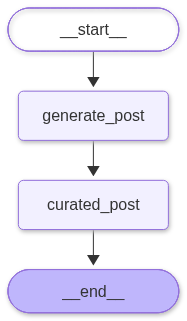

In [26]:
from IPython.display import Image, display

Image(pydantic_graph.get_graph().draw_mermaid_png())

In [28]:
pydantic_graph.invoke(
    {
        "topic":"Why async Python matters for LLM workflows",
        "post": "",
        "curated_post":"",
    }
)

{'topic': 'Why async Python matters for LLM workflows',
 'post': '🚀 **Why Async Python is a Game‑Changer for LLM Workflows** 🚀  \n\nIf you’ve been building pipelines around large language models (LLMs) – from prompt engineering and retrieval‑augmented generation to real‑time chat interfaces – you’ve probably hit the same bottleneck: **I/O latency**. Whether it’s dozens of API calls to OpenAI, hugging‑face endpoints, vector‑store queries, or streaming token responses, the traditional synchronous approach blocks your entire process while waiting for each request to finish.  \n\n### 🔑 The async advantage  \n1️⃣ **Maximize throughput** – With `asyncio`, `httpx` or `aiohttp`, you can fire off hundreds of LLM requests in parallel without spawning a thread per call. Your event loop keeps the CPU busy while the network does the heavy lifting.  \n2️⃣ **Lower latency for end‑users** – Streaming token generation (`await response.aiter_text()`) lets you start displaying partial outputs the moment 